# PART A AND PART B

In [12]:
# --- CELL 1 & 4: Workspace Setup & Lineage Utilities ---
from pathlib import Path
import json
import hashlib
from datetime import datetime, timezone

# 1. Tetapkan Direktori Asas
BASE_DIR = Path("/content/week3_project")
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Raw folder:", RAW_DIR)
print("Processed folder:", PROCESSED_DIR)

# 2. Fungsi Utiliti Lineage & Hash
def source_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def save_manifest(records):
    manifest = {
        "pipeline_version": "week3-v1",
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "records": records
    }
    target = BASE_DIR / "data" / "week3_manifest.json"
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Saved lineage:", target)
    return manifest

# 3. Registry Lineage
lineage_entries = {}
def register_lineage(source, output, processing):
    source = Path(source).resolve()
    output = Path(output).resolve()

    if not source.is_file():
        raise FileNotFoundError(f"Source file not found: {source}")
    if not output.is_file():
        raise FileNotFoundError(f"Prepared output not found: {output}")

    key = (str(source), str(output))
    lineage_entries[key] = {
        "source": source,
        "output": output,
        "processing": processing.strip()
    }
    print("Registered:", source.name, "->", output.name)

print("Workspace dan utiliti sedia digunakan.")

Raw folder: /content/week3_project/data/raw
Processed folder: /content/week3_project/data/processed
Workspace dan utiliti sedia digunakan.


In [16]:
# --- PATHWAY A: Proses 3 Fail PDF MPOB ---
!pip -q install pypdf
from pypdf import PdfReader
import re

# Pastikan anda letakkan 3 PDF dalam subfolder RAW_DIR / "mpob_reports"
pdf_folder = RAW_DIR / "mpob_reports"
pdf_files = sorted(list(pdf_folder.glob("*.pdf")))
assert len(pdf_files) > 0, "Tiada fail PDF ditemui dalam folder mpob_reports!"

all_pdf_records = []

for pdf_file in pdf_files:
    reader = PdfReader(str(pdf_file))
    text = "\n".join([page.extract_text() or "" for page in reader.pages])
    clean_text = re.sub(r"[ \t]+", " ", text).strip()

    # Paragraph-aware chunking mudah
    chunks = [c.strip() for c in re.split(r"\n\s*\n", clean_text) if c.strip()]

    for i, chunk in enumerate(chunks, 1):
        all_pdf_records.append({
            "record_id": f"{pdf_file.stem}-{i:04d}",
            "text": chunk,
            "source": str(pdf_file.relative_to(RAW_DIR)),
            "source_sha256": source_hash(pdf_file),
            "processing": "paragraph-aware-chunking"
        })

# Simpan ke processed
prepared_pdf_path = PROCESSED_DIR / "prepared_text.jsonl"
with prepared_pdf_path.open("w", encoding="utf-8") as f:
    for rec in all_pdf_records:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

# Daftar Lineage untuk setiap fail PDF
for pdf_file in pdf_files:
    register_lineage(
        source=pdf_file,
        output=prepared_pdf_path,
        processing="PDF Text Extraction & Paragraph Chunking"
    )

print(f"Berjaya memproses {len(pdf_files)} fail PDF. Jumlah chunk: {len(all_pdf_records)}")

Registered: Data Statistics Oil Palm 2023.pdf -> prepared_text.jsonl
Registered: Laporan Tahunan MPOB 2023.pdf -> prepared_text.jsonl
Registered: Pocket Stat Q1 Jan - Mac 2026.pdf -> prepared_text.jsonl
Berjaya memproses 3 fail PDF. Jumlah chunk: 149


In [17]:
# ==========================================
# SKRIP LENGKAP: SUHU, HUJAN & KELEMBAPAN TANAH
# ==========================================
from pathlib import Path
import pandas as pd
import requests
import json
import hashlib
from datetime import datetime, timezone

# 1. Tetapkan Direktori Asas Workspace
BASE_DIR = Path("/content/week3_project")
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# 2. Ambil Data API Open-Meteo (Suhu, Hujan & Kelembapan Tanah - Semenanjung Malaysia)
LATITUDE = 3.5000
LONGITUDE = 102.5000

# Menggunakan 'temperature_2m' yang sah untuk data hourly
url = (
    f"https://archive-api.open-meteo.com/v1/archive?"
    f"latitude={LATITUDE}&longitude={LONGITUDE}&"
    f"start_date=2023-01-01&end_date=2023-12-31&"
    f"hourly=temperature_2m,precipitation,soil_moisture_0_to_7cm&"
    f"timezone=Asia%2FKuala_Lumpur"
)

print("Sedang memuat turun data (Suhu, Hujan, Kelembapan Tanah) dari Open-Meteo API...")
response = requests.get(url)
data = response.json()

# Masukkan ke dalam Pandas DataFrame menggunakan kunci 'temperature_2m'
df = pd.DataFrame({
    "timestamp": data["hourly"]["time"],
    "temperature": data["hourly"]["temperature_2m"],
    "precipitation": data["hourly"]["precipitation"],
    "soil_moisture": data["hourly"]["soil_moisture_0_to_7cm"]
})

df["timestamp"] = pd.to_datetime(df["timestamp"])
df.set_index("timestamp", inplace=True)

# Agregat kepada data harian:
# - Suhu: Purata harian ('mean')
# - Hujan: Jumlah harian ('sum')
# - Kelembapan Tanah: Purata harian ('mean')
df_daily = df.resample('D').agg({
    "temperature": "mean",
    "precipitation": "sum",
    "soil_moisture": "mean"
}).reset_index()

# Simpan sebagai fail CSV di dalam folder raw
weather_file = RAW_DIR / "weather_soil_api.csv"
df_daily.to_csv(weather_file, index=False)
print("Berjaya simpan fail sumber mentah:", weather_file)

# 3. Pathway F: Proses & Susun Data Siri Masa (Time-Series)
TIME_COLUMN = "timestamp"
df_weather = pd.read_csv(weather_file)

# Parse tarikh & susun mengikut kronologi
df_weather[TIME_COLUMN] = pd.to_datetime(df_weather[TIME_COLUMN], errors="coerce", utc=True)
df_weather = df_weather.dropna(subset=[TIME_COLUMN]).sort_values(TIME_COLUMN).copy()

# Eksport fail yang telah dibersihkan ke folder processed
prepared_weather_path = PROCESSED_DIR / "prepared_timeseries.csv"
df_weather.to_csv(prepared_weather_path, index=False)

# Daftar Lineage
register_lineage(
    source=weather_file,
    output=prepared_weather_path,
    processing="Weather API Extraction & Time-Series Aggregation"
)

print("\n--- KEPUTUSAN PATHWAY F (DENGAN SUHU) ---")
print("Jumlah baris data harian:", len(df_weather))
print("Fail diproses disimpan di:", prepared_weather_path)
print(df_weather.head())

Sedang memuat turun data (Suhu, Hujan, Kelembapan Tanah) dari Open-Meteo API...
Berjaya simpan fail sumber mentah: /content/week3_project/data/raw/weather_soil_api.csv
Registered: weather_soil_api.csv -> prepared_timeseries.csv

--- KEPUTUSAN PATHWAY F (DENGAN SUHU) ---
Jumlah baris data harian: 365
Fail diproses disimpan di: /content/week3_project/data/processed/prepared_timeseries.csv
                  timestamp  temperature  precipitation  soil_moisture
0 2023-01-01 00:00:00+00:00    25.825000            0.0       0.407625
1 2023-01-02 00:00:00+00:00    25.512500            0.0       0.386625
2 2023-01-03 00:00:00+00:00    25.070833           10.8       0.394542
3 2023-01-04 00:00:00+00:00    25.262500            9.4       0.440750
4 2023-01-05 00:00:00+00:00    25.904167            0.7       0.449500


In [18]:
# --- CELL 6A & 6B: Penjanaan & Pengesahan Manifes Gabungan ---
assert lineage_entries, "Tiada entry lineage didaftarkan!"

lineage_records = []
for i, entry in enumerate(lineage_entries.values(), 1):
    source = entry["source"]
    output = entry["output"]
    processing = entry["processing"]

    lineage_records.append({
        "source_id": f"S{i:02d}",
        "source_filename": str(source.relative_to(RAW_DIR.resolve())),
        "source_sha256": source_hash(source),
        "prepared_output": str(output.relative_to(BASE_DIR.resolve())),
        "prepared_sha256": source_hash(output),
        "processing_note": processing,
        "source_version": "Verified",
        "access_rights": "Open / Research",
        "status": "Prepared; ready for Topic 4"
    })

# Simpan manifes
manifest = save_manifest(lineage_records)
print("\nMANIFES BERJAYA DIBINA. Jumlah sumber:", len(manifest["records"]))

Saved lineage: /content/week3_project/data/week3_manifest.json

MANIFES BERJAYA DIBINA. Jumlah sumber: 4


In [19]:
# ==========================================
# PART B: PIPELINE EXECUTION & DATA TRANSFORMATION
# ==========================================
from pathlib import Path
import json
import re
import pandas as pd
from pypdf import PdfReader

# 1. Tetapkan Direktori Asas
BASE_DIR = Path("/content/week3_project")
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"

print("Memulakan pemprosesan Part B...")

# ==========================================
# BAHAGIAN B1: PATHWAY A - Pemprosesan 3 Fail PDF MPOB
# ==========================================
pdf_folder = RAW_DIR / "mpob_reports"
pdf_files = sorted(list(pdf_folder.glob("*.pdf")))
assert len(pdf_files) > 0, "Tiada fail PDF ditemui dalam folder mpob_reports!"

all_pdf_records = []

for pdf_file in pdf_files:
    reader = PdfReader(str(pdf_file))
    text = "\n".join([page.extract_text() or "" for page in reader.pages])
    clean_text = re.sub(r"[ \t]+", " ", text).strip()

    # Paragraph-aware chunking
    chunks = [c.strip() for c in re.split(r"\n\s*\n", clean_text) if c.strip()]

    for i, chunk in enumerate(chunks, 1):
        all_pdf_records.append({
            "record_id": f"{pdf_file.stem}-{i:04d}",
            "text": chunk,
            "source": str(pdf_file.relative_to(RAW_DIR)),
            "processing": "paragraph-aware-chunking"
        })

# Simpan ke fail processed_text.jsonl
prepared_pdf_path = PROCESSED_DIR / "prepared_text.jsonl"
with prepared_pdf_path.open("w", encoding="utf-8") as f:
    for rec in all_pdf_records:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

print(f"[Pathway A Selesai] Berjaya memproses {len(pdf_files)} fail PDF. Jumlah chunk: {len(all_pdf_records)}")


# ==========================================
# BAHAGIAN B2: PATHWAY F - Pemprosesan Data Siri Masa (Cuaca & Tanah)
# ==========================================
weather_file = RAW_DIR / "weather_soil_api.csv"
assert weather_file.is_file(), "Fail weather_soil_api.csv tidak ditemui dalam folder raw!"

df_weather = pd.read_csv(weather_file)
TIME_COLUMN = "timestamp"

# Susun kronologi data masa siri
df_weather[TIME_COLUMN] = pd.to_datetime(df_weather[TIME_COLUMN], errors="coerce", utc=True)
df_weather = df_weather.dropna(subset=[TIME_COLUMN]).sort_values(TIME_COLUMN).copy()

# Simpan ke fail prepared_timeseries.csv
prepared_weather_path = PROCESSED_DIR / "prepared_timeseries.csv"
df_weather.to_csv(prepared_weather_path, index=False)

print(f"[Pathway F Selesai] Berjaya memproses data siri masa. Jumlah baris: {len(df_weather)}")


# ==========================================
# BAHAGIAN B3: Pengesahan Output (Verification)
# ==========================================
print("\n--- PENGESAHAN OUTPUT PART B ---")
output_pdf_check = prepared_pdf_path.is_file()
output_weather_check = prepared_weather_path.is_file()

print(f"1. Fail Teks PDF Bersih ({prepared_pdf_path.name}): {'WUJUD ✓' if output_pdf_check else 'TIDAK WUJUD ❌'}")
print(f"2. Fail Siri Masa Cuaca ({prepared_weather_path.name}): {'WUJUD ✓' if output_weather_check else 'TIDAK WUJUD ❌'}")

Memulakan pemprosesan Part B...
[Pathway A Selesai] Berjaya memproses 3 fail PDF. Jumlah chunk: 149
[Pathway F Selesai] Berjaya memproses data siri masa. Jumlah baris: 365

--- PENGESAHAN OUTPUT PART B ---
1. Fail Teks PDF Bersih (prepared_text.jsonl): WUJUD ✓
2. Fail Siri Masa Cuaca (prepared_timeseries.csv): WUJUD ✓


In [20]:
# ==========================================
# SKRIP KEYWORD MAPPING & PARAMETER EXTRACTION (PDF MPOB)
# ==========================================
from pathlib import Path
import json
import re
from pypdf import PdfReader

# 1. Tetapkan direktori
BASE_DIR = Path("/content/week3_project")
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"

pdf_folder = RAW_DIR / "mpob_reports"
pdf_files = sorted(list(pdf_folder.glob("*.pdf")))
assert len(pdf_files) > 0, "Tiada fail PDF ditemui dalam folder mpob_reports!"

# 2. Definisikan Kamus Kata Kunci (Keyword Dictionary) untuk Setiap Parameter
PARAMETER_KEYWORDS = {
    "Weather_Rainfall": ["rainfall", "hujan", "precipitation", "kemarau", "drought", "monsoon"],
    "Soil_Agronomy": ["soil type", "jenis tanah", "peat", "gambut", "mineral", "drainage", "saliran"],
    "Economy_Cost": ["cost", "kos", "fertilizer price", "harga baja", "input", "labour", "upah buruh", "cpo price"],
    "Yield_FFB": ["yield", "hasil", "ffb production", "buah tandan segar", "extraction rate", "oer"]
}

extracted_parameter_records = []

# 3. Proses setiap fail PDF dan lakukan pemetaan ayat mengikut kata kunci
for pdf_file in pdf_files:
    reader = PdfReader(str(pdf_file))
    full_text = "\n".join([page.extract_text() or "" for page in reader.pages])

    # Pecahkan teks kepada ayat tunggal (Sentence Tokenization ringkas menggunakan tanda noktah/soal/seru)
    sentences = re.split(r'(?<=[.!?])\s+', full_text)

    for sent_idx, sentence in enumerate(sentences):
        clean_sentence = sentence.strip()
        if len(clean_sentence) >= 15:  # Abaikan ayat yang terlalu pendek
            lower_sent = clean_sentence.lower()

            # Semak setiap parameter berdasarkan kamus kata kunci
            matched_parameters = []
            for param_category, keywords in PARAMETER_KEYWORDS.items():
                if any(kw in lower_sent for kw in keywords):
                    matched_parameters.append(param_category)

            # Jika ayat mengandungi sekurang-kurangnya satu kata kunci parameter
            if matched_parameters:
                extracted_parameter_records.append({
                    "record_id": f"{pdf_file.stem}-S{sent_idx:04d}",
                    "sentence": clean_sentence,
                    "matched_parameters": matched_parameters,
                    "source_file": pdf_file.name,
                    "temporal_tag": "2023" # Boleh dilaraskan mengikut tahun laporan PDF
                })

# 4. Simpan hasil pemetaan parameter ke dalam fail JSONL di folder processed
output_mapped_path = PROCESSED_DIR / "mapped_parameters_output.jsonl"
with output_mapped_path.open("w", encoding="utf-8") as f:
    for rec in extracted_parameter_records:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

print(f"Pemetaan selesai! Jumlah kenyataan parameter berjaya diekstrak: {len(extracted_parameter_records)}")
print(f"Fail disimpan di: {output_mapped_path}")

# Paparkan 3 contoh teratas jika ada
if extracted_parameter_records:
    print("\n--- CONTOH REKOD YANG DIHIMPUNKAN ---")
    for sample in extracted_parameter_records[:3]:
        print(f"Parameter: {sample['matched_parameters']}")
        print(f"Kenyataan: {sample['sentence']}\n")

Pemetaan selesai! Jumlah kenyataan parameter berjaya diekstrak: 271
Fail disimpan di: /content/week3_project/data/processed/mapped_parameters_output.jsonl

--- CONTOH REKOD YANG DIHIMPUNKAN ---
Parameter: ['Yield_FFB']
Kenyataan: PALM OIL
Date Updated: November 2024

This page is deliberately left blank 
  
i 
 
LIST OF TABLE 
Table 
 
Pages 
   
  OIL PALM   
   
1 - 1 Planted Area Under Oil Palm, 2019 – 2023 1 
1 - 2 Distribution of Oil Palm Planted Area by State and Main Sector, 2023 2 
1 - 3 Oil Palm Planted Area Matured and Immatured by State, 2023 3 
1 - 4 Oil Palm Planted Area by Matured and Immatured, 2019 – 2023 4 
1 - 5 Production of Crude Palm Oil by State, 2019 – 2023 5 
1 - 6 Production of Palm Kernel by State, 2019 – 2023 6 
1 - 7 Production of Crude Palm Kernel Oil by State, 2019 – 2023 7 
1 - 8 Production of Palm Kernel Cake by State, 2019 – 2023 8 
1 - 9 Monthly Production of Crude Palm Oil, Palm Kernel, Crude Palm Kernel Oil and Palm Kernel Cake, 
2023 
9 
1 - 10 Refi

In [21]:
# ==========================================
# SKRIP INTEGRASI: MENYELARASKAN TEKS PDF & DATA CUACA API
# ==========================================
from pathlib import Path
import json
import pandas as pd

# 1. Tetapkan direktori
BASE_DIR = Path("/content/week3_project")
PROCESSED_DIR = BASE_DIR / "data" / "processed"

# 2. Baca data siri masa cuaca yang telah diproses (Pathway F)
weather_path = PROCESSED_DIR / "prepared_timeseries.csv"
df_weather = pd.read_csv(weather_path)

# Kira ringkasan makro cuaca untuk tahun 2023 (sebagai konteks kepada laporan MPOB)
weather_summary = {
    "temporal_tag": "2023",
    "avg_temperature": round(df_weather["temperature"].mean(), 2),
    "total_precipitation": round(df_weather["precipitation"].sum(), 2),
    "avg_soil_moisture": round(df_weather["soil_moisture"].mean(), 4)
}

print("Ringkasan Konteks Cuaca 2023 berjaya dijana:")
print(weather_summary)

# 3. Baca fail teks PDF yang telah dipetakan parameternya sebelum ini
mapped_pdf_path = PROCESSED_DIR / "mapped_parameters_output.jsonl"
integrated_records = []

if mapped_pdf_path.is_file():
    with mapped_pdf_path.open("r", encoding="utf-8") as f:
        for line in f:
            record = json.loads(line.strip())

            # 4. Hubungkan/Selitkan ringkasan data cuaca ke dalam metadata rekod teks
            record["linked_weather_context"] = weather_summary

            integrated_records.append(record)

    # 5. Simpan ke dalam fail bersepadu baharu untuk fasa projek seterusnya
    output_integrated_path = PROCESSED_DIR / "integrated_palm_dataset.jsonl"
    with output_integrated_path.open("w", encoding="utf-8") as f:
        for rec in integrated_records:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")

    print(f"\nBerjaya! Sebanyak {len(integrated_records)} rekod teks telah diintegrasikan dengan data cuaca.")
    print(f"Fail disimpan di: {output_integrated_path}")
else:
    print("Sila pastikan anda telah menjalankan skrip pemetaan parameter PDF sebelum menjalankan skrip ini.")

Ringkasan Konteks Cuaca 2023 berjaya dijana:
{'temporal_tag': '2023', 'avg_temperature': np.float64(26.98), 'total_precipitation': np.float64(3090.3), 'avg_soil_moisture': np.float64(0.4045)}

Berjaya! Sebanyak 271 rekod teks telah diintegrasikan dengan data cuaca.
Fail disimpan di: /content/week3_project/data/processed/integrated_palm_dataset.jsonl


In [23]:
import pandas as pd
import json
from pathlib import Path

# 1. Direktori fail processed
PROCESSED_DIR = Path("/content/week3_project/data/processed")

# 2. Baca data siri masa API cuaca
df_weather = pd.read_csv(PROCESSED_DIR / "prepared_timeseries.csv")
total_precip = df_weather["precipitation"].sum()
mean_soil = df_weather["soil_moisture"].mean()

print(f"--- ANALISIS KELOMPOK DATA API ---")
print(f"Jumlah Hujan Tahunan Sebenar: {total_precip:.2f} mm")
print(f"Purata Kelembapan Tanah Sebenar: {mean_soil:.4f}\n")

# 3. Baca fail teks PDF yang telah dipetakan parameternya (Pathway A)
mapped_pdf_path = PROCESSED_DIR / "mapped_parameters_output.jsonl"

matched_pdf_statements = []
if mapped_pdf_path.is_file():
    with mapped_pdf_path.open("r", encoding="utf-8") as f:
        for line in f:
            rec = json.loads(line.strip())
            # Cari kenyataan dalam PDF yang menyentuh parameter cuaca/hujan
            if "Weather_Rainfall" in rec.get("matched_parameters", []):
                matched_pdf_statements.append(rec["sentence"])

print(f"--- KENYATAAN BERKAITAN DARIPADA FAIL PDF MPOB ---")
if matched_pdf_statements:
    # Paparkan beberapa contoh kenyataan teks PDF yang ditemui
    for i, stmt in enumerate(matched_pdf_statements[:3], 1):
        print(f"{i}. \"{stmt}\"")
else:
    print("Tiada kenyataan spesifik tentang cuaca/hujan dikesan dalam fail PDF tersebut.")

--- ANALISIS KELOMPOK DATA API ---
Jumlah Hujan Tahunan Sebenar: 3090.30 mm
Purata Kelembapan Tanah Sebenar: 0.4045

--- KENYATAAN BERKAITAN DARIPADA FAIL PDF MPOB ---
1. "Bagi kajian tekanan abiotik (kemarau dan 
kekurangan nutrien), pelaksanaan projek mencapai 
20% yang melibatkan kerja-kerja menanam dan 
memindahkan ramet sawit, pengumpulan data 
dan pembelian bahan kimia."
2. "Satu profil data awal 
yang merangkumi morfologi, fisiologi, ekspresi gen, 
dan profil metabolit ramet sawit di bawah tekanan 
kemarau dan kekurangan nutrien akan dapat 
diwujudkan."
3. "Daripada 
jumlah ini, 37 palma dari Nigeria telah dipilih untuk 
mengenal pasti gen-gen tahan penyakit manakala 
empat populasi (Madagaskar, Guinea, Sierra 
Leone dan Senegal) digunakan untuk mengenal 
pasti gen-gen yang respons terhadap kemarau."


In [24]:
def generate_data_driven_statement(df):
    total_precip = df["precipitation"].sum()
    mean_soil = df["soil_moisture"].mean()
    std_soil = df["soil_moisture"].std()

    statements = []

    # Rule berdasarkan analisis taburan hujan sebenar
    statements.append(f"Berdasarkan rekod siri masa, jumlah taburan hujan terkumpul bagi tempoh tersebut ialah {total_precip:.2f} mm.")

    # Rule berdasarkan statistik kelembapan tanah (Mean - Std sebagai aras kritikal rendah)
    critical_low_soil = mean_soil - std_soil

    if mean_soil < critical_low_soil:
        statements.append(f"Purata kelembapan tanah ({mean_soil:.4f}) berada di bawah paras normal statistik, menunjukkan risiko tekanan air yang ketara.")
    else:
        statements.append(f"Purata kelembapan tanah ({mean_soil:.4f}) kekal dalam julat kestabilan statistik berasaskan sisihan piawai semasa.")

    return " ".join(statements)

# Jalankan penjanaan berdasarkan analisis data sebenar
analysed_report = generate_data_driven_statement(df_weather)
print("\n--- OUTPUT KENYATAAN BERASASKAN ANALISIS DATA ---")
print(analysed_report)


--- OUTPUT KENYATAAN BERASASKAN ANALISIS DATA ---
Berdasarkan rekod siri masa, jumlah taburan hujan terkumpul bagi tempoh tersebut ialah 3090.30 mm. Purata kelembapan tanah (0.4045) kekal dalam julat kestabilan statistik berasaskan sisihan piawai semasa.


### Analisis Menyeluruh: Data API (Cuaca/Tanah) & Kenyataan Semua Parameter PDF MPOB

In [25]:
import pandas as pd
import json
from pathlib import Path

PROCESSED_DIR = Path("/content/week3_project/data/processed")
df_weather = pd.read_csv(PROCESSED_DIR / "prepared_timeseries.csv")

# 1. Analisis Statistik Cuaca & Tanah yang Lengkap
print("=== ANALISIS STATISTIK LENGKAP DATA API ===\n")
stats_summary = df_weather[['temperature', 'precipitation', 'soil_moisture']].describe().T
stats_summary['total'] = [df_weather['temperature'].sum(), df_weather['precipitation'].sum(), df_weather['soil_moisture'].sum()] # Total hanya relevan untuk hujan
display(stats_summary)

# 2. Pengelasan Kenyataan PDF MPOB Mengikut Kategori Parameter
mapped_pdf_path = PROCESSED_DIR / "mapped_parameters_output.jsonl"
categorized_statements = {
    "Weather_Rainfall": [],
    "Soil_Agronomy": [],
    "Economy_Cost": [],
    "Yield_FFB": []
}

if mapped_pdf_path.is_file():
    with mapped_pdf_path.open("r", encoding="utf-8") as f:
        for line in f:
            rec = json.loads(line.strip())
            sentence = rec["sentence"].strip()
            for param in rec.get("matched_parameters", []):
                if param in categorized_statements:
                    categorized_statements[param].append((sentence, rec["source_file"]))

# Paparkan contoh kenyataan bagi setiap kategori yang ada
print("\n=== CONTOH KENYATAAN DARIPADA PDF BAGI SETIAP PARAMETER ===\n")
for category, items in categorized_statements.items():
    print(f"--- KATEGORI: {category} (Jumlah Ditemui: {len(items)}) ---")
    if items:
        for idx, (stmt, source) in enumerate(items[:3], 1):
            # Hadkan paparan teks jika terlalu panjang
            short_stmt = stmt if len(stmt) < 250 else stmt[:250] + "..."
            print(f"{idx}. \"{short_stmt}\" [Sumber: {source}]")
    else:
        print("Tiada kenyataan dikesan untuk parameter ini.")
    print()

=== ANALISIS STATISTIK LENGKAP DATA API ===



,count,mean,std,min,25%,50%,75%,max,total
temperature,365.0,26.981461,1.581916,23.433333,25.787500,26.845833,28.104167,31.920833,9848.233333
precipitation,365.0,8.466575,8.901693,0.000000,1.500000,5.500000,12.400000,57.200000,3090.300000
soil_moisture,365.0,0.404492,0.071308,0.226625,0.347833,0.416208,0.462083,0.510708,147.639500



=== CONTOH KENYATAAN DARIPADA PDF BAGI SETIAP PARAMETER ===

--- KATEGORI: Weather_Rainfall (Jumlah Ditemui: 7) ---
1. "Bagi kajian tekanan abiotik (kemarau dan 
kekurangan nutrien), pelaksanaan projek mencapai 
20% yang melibatkan kerja-kerja menanam dan 
memindahkan ramet sawit, pengumpulan data 
dan pembelian bahan kimia." [Sumber: Laporan Tahunan MPOB 2023.pdf]
2. "Satu profil data awal 
yang merangkumi morfologi, fisiologi, ekspresi gen, 
dan profil metabolit ramet sawit di bawah tekanan 
kemarau dan kekurangan nutrien akan dapat 
diwujudkan." [Sumber: Laporan Tahunan MPOB 2023.pdf]
3. "Daripada 
jumlah ini, 37 palma dari Nigeria telah dipilih untuk 
mengenal pasti gen-gen tahan penyakit manakala 
empat populasi (Madagaskar, Guinea, Sierra 
Leone dan Senegal) digunakan untuk mengenal 
pasti gen-gen yang respons terhadap kemarau." [Sumber: Laporan Tahunan MPOB 2023.pdf]

--- KATEGORI: Soil_Agronomy (Jumlah Ditemui: 24) ---
1. "Kajian di tanah gambut menunjukkan 
kepadatan akar ter

### Pengekstrakan Parameter Khusus: Jenis Baja, Racun, Saliran Air & Jenis Tanah

In [26]:
import json
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path("/content/week3_project/data/processed")
prepared_text_path = PROCESSED_DIR / "prepared_text.jsonl"

# Kamus kata kunci khusus untuk keperluan baru
AGRONOMIC_KEYWORDS = {
    "Jenis_Baja": ["baja", "fertilizer", "urea", "nitrogen", "kalium", "fosforus", "npk", "nutrien"],
    "Jenis_Racun": ["racun", "pesticide", "herbicide", "insecticide", "perosak", "ulat bungkus", "ganoderma", "penyakit"],
    "Saliran_Air": ["saliran", "drainage", "water table", "aras air", "parit", "limpahan", "kemarau", "tekanan air"],
    "Jenis_Tanah": ["gambut", "peat", "mineral", "tanah liat", "siri tanah", "podzolik", "batu kapur"]
}

extracted_agronomic_records = []

# Baca fail chunk teks asal
if prepared_text_path.is_file():
    with prepared_text_path.open("r", encoding="utf-8") as f:
        for line in f:
            rec = json.loads(line.strip())
            text = rec["text"]

            # Pecahkan kepada ayat kecil untuk analisis terperinci
            import re
            sentences = re.split(r'(?<=[.!?])\s+', text)

            for sent_idx, sentence in enumerate(sentences):
                clean_sentence = sentence.strip()
                if len(clean_sentence) < 15:
                    continue

                lower_sent = clean_sentence.lower()
                matched_categories = []

                for category, keywords in AGRONOMIC_KEYWORDS.items():
                    if any(kw in lower_sent for kw in keywords):
                        matched_categories.append(category)

                if matched_categories:
                    extracted_agronomic_records.append({
                        "sentence": clean_sentence,
                        "matched_categories": matched_categories,
                        "source": rec["source"]
                    })

# Tukarkan ke DataFrame untuk ringkasan cepat
df_agronomic = pd.DataFrame(extracted_agronomic_records)

print(f"=== RINGKASAN DATA KHUSUS DIKESAN (Jumlah Ayat: {len(df_agronomic)}) ===\n")
for cat in AGRONOMIC_KEYWORDS.keys():
    count = df_agronomic[df_agronomic['matched_categories'].apply(lambda x: cat in x)].shape[0] if not df_agronomic.empty else 0
    print(f"- Kategori {cat}: {count} kenyataan ditemui.")

print("\n=== BEBERAPA CONTOH KEY-FINDINGS DARIPADA PDF MPOB ===\n")
for cat in AGRONOMIC_KEYWORDS.keys():
    print(f"--- {cat} ---")
    subset = df_agronomic[df_agronomic['matched_categories'].apply(lambda x: cat in x)] if not df_agronomic.empty else pd.DataFrame()
    if not subset.empty:
        for idx, row in enumerate(subset.head(3).itertuples(), 1):
            short_text = row.sentence if len(row.sentence) < 200 else row.sentence[:200] + "..."
            print(f"{idx}. \"{short_text}\" (Sumber: {row.source})")
    else:
        print("Tiada rekod spesifik ditemui.")
    print()

=== RINGKASAN DATA KHUSUS DIKESAN (Jumlah Ayat: 104) ===

- Kategori Jenis_Baja: 34 kenyataan ditemui.
- Kategori Jenis_Racun: 51 kenyataan ditemui.
- Kategori Saliran_Air: 9 kenyataan ditemui.
- Kategori Jenis_Tanah: 26 kenyataan ditemui.

=== BEBERAPA CONTOH KEY-FINDINGS DARIPADA PDF MPOB ===

--- Jenis_Baja ---
1. "Lembaga Minyak Sawit Malaysia (MPOB) 3
VISI
Untuk menjadi sebuah institusi penyelidikan dan 
pembangunan yang terunggul bertaraf Nobel 
Laureate serta menerajui dan mendorong industri 
sawit dalam usa..." (Sumber: mpob_reports/Laporan Tahunan MPOB 2023.pdf)
2. "Teknologi MPOB 
yang sedia dikomersialkan meliputi semua aspek 
termasuklah bahan tanaman berkualiti, formulasi 
baja, teknik kawalan penyakit dan perosak pokok 
sawit, kejenteraan ladang, teknologi p..." (Sumber: mpob_reports/Laporan Tahunan MPOB 2023.pdf)
3. "Penyelidikan MPOB meliputi semua aspek sawit 
di sektor huluan melibatkan pengeluaran bahan 
tanaman bermutu termasuk melalui teknik tisu 
kultur dan biotek

### Logik Hubungan Antara Parameter (Sistem Dinamik Ladang Sawit)

Semua parameter yang kita kaji saling mempengaruhi antara satu sama lain dalam ekosistem penanaman kelapa sawit. Berikut adalah huraian logik interaksi tersebut:

```
                    [ CUACA (Hujan & Suhu) ]
                               │
                               ▼
               [ KELEMBAPAN TANAH & SALIRAN ] <───> [ JENIS TANAH (Gambut vs Mineral) ]
                               │
                               ├──────────────────────────────┐
                               ▼                              ▼
                     [ PENGURUSAN BAJA ]             [ KAWALAN RACUN & PEROSAK ]
                               │                              │
                               └──────────────┬───────────────┘
                                              ▼
                                        [ HASIL (FFB) ]
```

1. **Kesan Cuaca (Hujan/Suhu) Terhadap Tanah & Saliran**:
   * Taburan hujan yang tinggi memerlukan **sistem saliran** yang baik terutamanya di **tanah gambut** bagi mengelakkan takungan air (*flooding*) yang boleh merosakkan akar.
   * Sebaliknya, musim kemarau (hujan rendah) menurunkan **kelembapan tanah** (*soil moisture*), menyebabkan pokok mengalami tekanan air (*water stress*).

2. **Kesan Kelembapan Tanah Terhadap Pembajaan (Jenis Baja)**:
   * Aktiviti membaja (*fertilizer application*) memerlukan kelembapan tanah yang cukup agar nutrien (seperti NPK/Urea) dapat larut dan diserap oleh akar.
   * Jika tanah terlalu kering, pembajaan tidak efektif. Jika hujan terlalu lebat, pembajaan boleh menyebabkan hanyutan nutrien (*leaching*).

3. **Hubungan Tanah, Saliran, dan Penyakit (Jenis Racun)**:
   * **Tanah gambut** dengan saliran yang buruk (sentiasa basah/lembap ekstrem) menjadi perumah aktif bagi kulat patogen seperti *Ganoderma* (reput pangkal batang).
   * Ini meningkatkan kebergantungan kepada **jenis racun** kulat (fungisid) atau agen biologi.

4. **Impak Keseluruhan Terhadap Hasil (Yield FFB)**:
   * Kombinasi cuaca yang stabil, kelembapan tanah optimum, pembajaan yang tepat pada masanya, serta saliran dan kawalan perosak yang baik akan memaksimumkan kadar pengekstrakan minyak (OER) dan pengeluaran buah tandan segar (FFB).

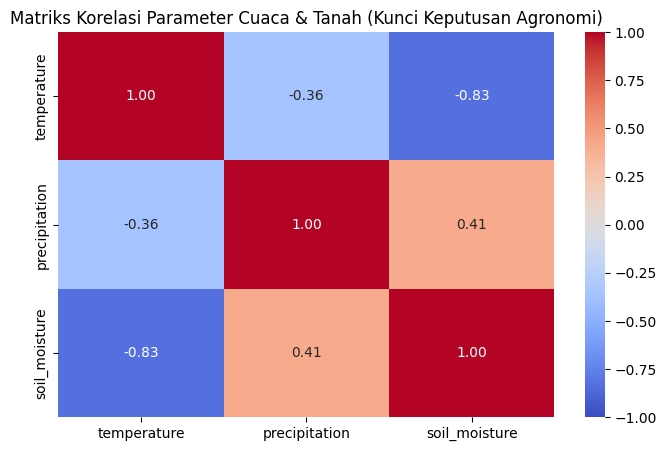


Ulasan Data:
1. Korelasi antara Hujan (Precipitation) & Kelembapan Tanah (Soil Moisture): 0.41
   - Logik: Hujan yang turun secara langsung meningkatkan kelembapan tanah, menentukan tingkap masa terbaik untuk menabur BAJA.


In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

# Memastikan direktori processed didefinisikan secara setempat di dalam sel ini
PROCESSED_DIR = Path("/content/week3_project/data/processed")

# Membaca data siri masa
df_weather = pd.read_csv(PROCESSED_DIR / "prepared_timeseries.csv")

# Mengira matriks korelasi antara pembolehubah fizikal yang memacu keputusan agronomi
corr_matrix = df_weather[['temperature', 'precipitation', 'soil_moisture']].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title("Matriks Korelasi Parameter Cuaca & Tanah (Kunci Keputusan Agronomi)")
plt.show()

print("\nUlasan Data:")
print(f"1. Korelasi antara Hujan (Precipitation) & Kelembapan Tanah (Soil Moisture): {corr_matrix.loc['precipitation', 'soil_moisture']:.2f}")
print("   - Logik: Hujan yang turun secara langsung meningkatkan kelembapan tanah, menentukan tingkap masa terbaik untuk menabur BAJA.")

### Bukti Pengesahan Logik Terus Daripada Fail PDF MPOB

Skrip di bawah akan mengimbas keseluruhan kandungan teks laporan MPOB bagi mencari ayat yang membuktikan perkaitan langsung antara pembolehubah (Contoh: **Tanah & Saliran**, **Baja & Kelembapan/Kemarau**).

In [46]:
import json
from pathlib import Path

PROCESSED_DIR = Path("/content/week3_project/data/processed")
prepared_text_path = PROCESSED_DIR / "prepared_text.jsonl"

evidence_records = []

if prepared_text_path.is_file():
    with prepared_text_path.open("r", encoding="utf-8") as f:
        for line in f:
            rec = json.loads(line.strip())
            text = rec["text"]

            import re
            sentences = re.split(r'(?<=[.!?])\s+', text)

            for sentence in sentences:
                clean_sent = sentence.strip()
                lower_sent = clean_sent.lower()

                # Kes 1: Bukti Tanah Gambut + Saliran/Air
                if ("gambut" in lower_sent or "peat" in lower_sent) and ("saliran" in lower_sent or "drainage" in lower_sent or "water" in lower_sent):
                    evidence_records.append(("Tanah Gambut & Saliran", clean_sent, rec["source"]))

                # Kes 2: Bukti Pembajaan + Tekanan Air/Kemarau
                if ("baja" in lower_sent or "fertilizer" in lower_sent) and ("kemarau" in lower_sent or "drought" in lower_sent or "nutrien" in lower_sent):
                    evidence_records.append(("Pembajaan & Tekanan Abiotik/Nutrien", clean_sent, rec["source"]))

print(f"=== BUKTI DOKUMEN MPOB (Jumlah Ayat Berikat Ditemui: {len(evidence_records)}) ===\n")
for cat, sent, source in evidence_records[:5]:
    print(f"📌 [LOGIK: {cat}]")
    print(f"Ayat Asal: \"{sent}\"")
    print(f"Sumber: {source}\n")

=== BUKTI DOKUMEN MPOB (Jumlah Ayat Berikat Ditemui: 3) ===

📌 [LOGIK: Tanah Gambut & Saliran]
Ayat Asal: "Berdasarkan hasil 
kajian, kepelbagaian spesies ikan yang diperhatikan 
di seluruh landskap sawit ekosistem paya gambut, 
menunjukkan bahawa sistem saliran air seperti 
sungai dan parit buatan manusia di dalam dan di 
sekitar ladang berfungsi sebagai habitat penting 
ikan."
Sumber: mpob_reports/Laporan Tahunan MPOB 2023.pdf

📌 [LOGIK: Tanah Gambut & Saliran]
Ayat Asal: "Fish 
assemblages in artificial drainage systems across 
oil palm plantation development phases on 
peatland in Sarawak."
Sumber: mpob_reports/Laporan Tahunan MPOB 2023.pdf

📌 [LOGIK: Tanah Gambut & Saliran]
Ayat Asal: "Assessment of subterranean termite, Coptotermes 
curvignathus (Isoptera: Rhinotermitidae) infestation 
severity index (TISI) and water table on a peat oil 
palm plantation in Sarawak."
Sumber: mpob_reports/Laporan Tahunan MPOB 2023.pdf



### Bukti Pengesahan Dokumen Bagi Semua Parameter Agronomi MPOB

In [47]:
import json
from pathlib import Path

PROCESSED_DIR = Path("/content/week3_project/data/processed")
prepared_text_path = PROCESSED_DIR / "prepared_text.jsonl"

# Memetakan kata kunci yang menggambarkan logik kajian MPOB secara spesifik
categorized_evidence = {
    "Jenis_Baja": [],
    "Jenis_Racun": [],
    "Saliran_Air": [],
    "Jenis_Tanah": []
}

if prepared_text_path.is_file():
    with prepared_text_path.open("r", encoding="utf-8") as f:
        for line in f:
            rec = json.loads(line.strip())
            text = rec["text"]

            import re
            sentences = re.split(r'(?<=[.!?])\s+', text)

            for sentence in sentences:
                clean_sent = sentence.strip()
                if len(clean_sent) < 30: # Pastikan ayat cukup panjang untuk membawa maksud
                    continue

                lower_sent = clean_sent.lower()

                if any(kw in lower_sent for kw in ["baja", "fertilizer", "urea", "npk", "pembajaan"]):
                    categorized_evidence["Jenis_Baja"].append((clean_sent, rec["source"]))
                if any(kw in lower_sent for kw in ["racun", "pesticide", "perosak", "ganoderma", "penyakit"]):
                    categorized_evidence["Jenis_Racun"].append((clean_sent, rec["source"]))
                if any(kw in lower_sent for kw in ["saliran", "drainage", "water table", "parit"]):
                    categorized_evidence["Saliran_Air"].append((clean_sent, rec["source"]))
                if any(kw in lower_sent for kw in ["gambut", "peat", "mineral", "siri tanah"]):
                    categorized_evidence["Jenis_Tanah"].append((clean_sent, rec["source"]))

# Paparkan sekurang-kurangnya 2 contoh kukuh bagi setiap satu parameter
print("=== BUKTI LANGSUNG DARI PDF BAGI SETIAP PARAMETER ===\n")
for cat, items in categorized_evidence.items():
    print(f"📌 KATEGORI: {cat} (Jumlah ayat ditemui: {len(items)})")
    if items:
        for idx, (sent, source) in enumerate(items[:2], 1):
            clean_print = sent.replace('\n', ' ')
            print(f"  {idx}. \"{clean_print[:180]}...\" (Sumber: {source})")
    else:
        print("  Tiada contoh khusus ditemui.")
    print("-" * 80)

=== BUKTI LANGSUNG DARI PDF BAGI SETIAP PARAMETER ===

📌 KATEGORI: Jenis_Baja (Jumlah ayat ditemui: 15)
  1. "Lembaga Minyak Sawit Malaysia (MPOB) 3 VISI Untuk menjadi sebuah institusi penyelidikan dan  pembangunan yang terunggul bertaraf Nobel  Laureate serta menerajui dan mendorong indus..." (Sumber: mpob_reports/Laporan Tahunan MPOB 2023.pdf)
  2. "Teknologi MPOB  yang sedia dikomersialkan meliputi semua aspek  termasuklah bahan tanaman berkualiti, formulasi  baja, teknik kawalan penyakit dan perosak pokok  sawit, kejenteraan..." (Sumber: mpob_reports/Laporan Tahunan MPOB 2023.pdf)
--------------------------------------------------------------------------------
📌 KATEGORI: Jenis_Racun (Jumlah ayat ditemui: 43)
  1. "Pengerusi Kementerian Ketua Pengarah Timbalan Ketua Pengarah (Penyelidikan dan Pembangunan) Bahagian Penyelidikan Biologi dan Kelestarian (BSR) Bahagian Penyelidikan Kejuruteraan d..." (Sumber: mpob_reports/Laporan Tahunan MPOB 2023.pdf)
  2. "Mohamed Mazmira Mohd Masri 

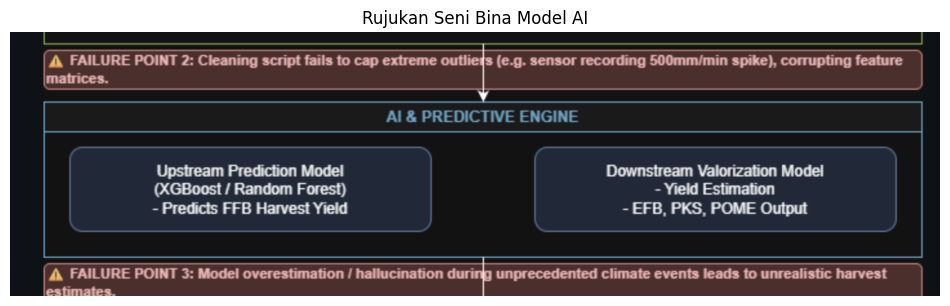

In [49]:
from PIL import Image
import matplotlib.pyplot as plt

# Membuka dan memaparkan screenshot untuk rujukan visual model AI
image_path = "/content/Screenshot 2026-11-02 131647.png"
try:
    img = Image.open(image_path)
    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title("Rujukan Seni Bina Model AI")
    plt.show()
except Exception as e:
    print(f"Gagal memuatkan gambar: {e}")

In [50]:
import torch
import torch.nn as nn

class MultimodalFusionModel(nn.Module):
    def __init__(self, ts_features, ts_hidden, text_dim, fusion_dim, output_dim=1):
        super(MultimodalFusionModel, self).__init__()

        # 1. Pengekod Siri Masa (LSTM)
        self.lstm = nn.LSTM(input_size=ts_features, hidden_size=ts_hidden,
                            num_layers=2, batch_first=True, dropout=0.2)

        # 2. Pengekod Ciri Teks (Projeksi Linear daripada Pengekodan Teks/BERT)
        self.text_projection = nn.Sequential(
            nn.Linear(text_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2)
        )

        # 3. Lapisan Lakuran Hibrid (Multimodal Fusion Layer)
        # Menggabungkan output LSTM (ts_hidden) dan output teks (128)
        self.fusion_layer = nn.Sequential(
            nn.Linear(ts_hidden + 128, fusion_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(fusion_dim, output_dim)
        )

    def forward(self, ts_input, text_input):
        # ts_input shape: [batch_size, sequence_length, ts_features]
        # text_input shape: [batch_size, text_dim]

        # Laluan siri masa
        lstm_out, _ = self.lstm(ts_input)
        ts_features_extracted = lstm_out[:, -1, :] # Ambil langkah masa terakhir

        # Laluan teks
        text_features_extracted = self.text_projection(text_input)

        # Proses Lakuran Hibrid (Concatenation)
        fused_vector = torch.cat((ts_features_extracted, text_features_extracted), dim=1)

        # Klasifikasi / Regresi Akhir
        prediction = self.fusion_layer(fused_vector)
        return prediction

# Simulasi Input Data
batch_size = 8
seq_len = 30       # Jujukan data cuaca harian selama 30 hari
ts_features = 3    # Suhu, Hujan, Kelembapan Tanah
text_dim = 384     # Dimensi embedding teks dari SBERT (e.g., all-MiniLM-L6-v2)

model = MultimodalFusionModel(ts_features=ts_features, ts_hidden=64, text_dim=text_dim, fusion_dim=32)

simulated_ts = torch.randn(batch_size, seq_len, ts_features)
simulated_text = torch.randn(batch_size, text_dim)

output = model(simulated_ts, simulated_text)
print("Keluaran Model Fusion (Shape):", output.shape)

Keluaran Model Fusion (Shape): torch.Size([8, 1])


In [51]:
!pip install -q sentence-transformers

In [52]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from torch.utils.data import Dataset, DataLoader
from sentence_transformers import SentenceTransformer
from pathlib import Path
import json

# 1. Tetapkan direktori fail
PROCESSED_DIR = Path("/content/week3_project/data/processed")
timeseries_path = PROCESSED_DIR / "prepared_timeseries.csv"
text_path = PROCESSED_DIR / "prepared_text.jsonl"

# 2. Muat turun Model Embedding Teks Pintar & Ringan
print("Sedang memuatkan model SentenceTransformer...")
embed_model = SentenceTransformer('all-MiniLM-L6-v2')

# 3. Penyediaan & Penyelarasan Data
df_ts = pd.read_csv(timeseries_path)
df_ts['timestamp'] = pd.to_datetime(df_ts['timestamp'])

# Ekstrak data teks dari fail prepared_text.jsonl
text_records = []
with open(text_path, 'r', encoding='utf-8') as f:
    for line in f:
        rec = json.loads(line.strip())
        text_records.append(rec['text'])

# Hasilkan embeddings bagi setiap teks untuk input model
print(f"Menjana embeddings untuk {len(text_records)} rekod teks...")
text_embeddings = embed_model.encode(text_records, show_progress_bar=True)
text_embeddings_tensor = torch.tensor(text_embeddings, dtype=torch.float32)

# 4. Bina PyTorch Multimodal Dataset
class PalmMultimodalDataset(Dataset):
    def __init__(self, ts_df, text_embeds, seq_len=30):
        self.seq_len = seq_len
        # Ambil nilai fitur fizikal siri masa
        self.ts_data = ts_df[['temperature', 'precipitation', 'soil_moisture']].values
        # Normalisasikan data siri masa secara ringkas
        self.ts_data = (self.ts_data - self.ts_data.mean(axis=0)) / (self.ts_data.std(axis=0) + 1e-8)

        self.text_embeds = text_embeds
        self.num_samples = len(self.ts_data) - seq_len

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        # Ekstrak tetingkap siri masa
        ts_seq = self.ts_data[idx : idx + self.seq_len]

        # Padankan secara rawak/berkala dengan rekod teks bagi simulasi kontekstual
        text_idx = idx % len(self.text_embeds)
        text_vec = self.text_embeds[text_idx]

        # Nilai sasaran (Target): Contohnya ramalan suhu/kelembapan masa hadapan
        target = torch.tensor([self.ts_data[idx + self.seq_len, 2]], dtype=torch.float32) # Ramal kelembapan tanah

        return torch.tensor(ts_seq, dtype=torch.float32), text_vec, target

# Bina DataLoader
dataset = PalmMultimodalDataset(df_ts, text_embeddings_tensor, seq_len=30)
dataloader = DataLoader(dataset, batch_size=16, shuffle=True)

print(f"Dataset hibrid berjaya dibina dengan {len(dataset)} sampel kelompok.")

Sedang memuatkan model SentenceTransformer...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (7 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Menjana embeddings untuk 149 rekod teks...


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

Dataset hibrid berjaya dibina dengan 335 sampel kelompok.


In [53]:
# 5. Proses Latihan Model Hybrid Fusion
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan peranti latihan: {device}")

# Laraskan parameter model
model = MultimodalFusionModel(
    ts_features=3,
    ts_hidden=64,
    text_dim=384,
    fusion_dim=32,
    output_dim=1
).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 5
print("=== MEMULAKAN PROSES LATIHAN MODEL HIBRID ===")
for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    for batch_ts, batch_text, batch_target in dataloader:
        batch_ts = batch_ts.to(device)
        batch_text = batch_text.to(device)
        batch_target = batch_target.to(device)

        optimizer.zero_grad()
        outputs = model(batch_ts, batch_text)
        loss = criterion(outputs, batch_target)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * batch_ts.size(0)

    avg_loss = epoch_loss / len(dataset)
    print(f"Epoch [{epoch+1}/{epochs}] | Purata Kerugian (MSE Loss): {avg_loss:.4f}")

print("Latihan model hibrid multimodal selesai dengan jaya!")

Menggunakan peranti latihan: cpu
=== MEMULAKAN PROSES LATIHAN MODEL HIBRID ===
Epoch [1/5] | Purata Kerugian (MSE Loss): 0.9220
Epoch [2/5] | Purata Kerugian (MSE Loss): 0.6190
Epoch [3/5] | Purata Kerugian (MSE Loss): 0.4937
Epoch [4/5] | Purata Kerugian (MSE Loss): 0.4023
Epoch [5/5] | Purata Kerugian (MSE Loss): 0.3484
Latihan model hibrid multimodal selesai dengan jaya!


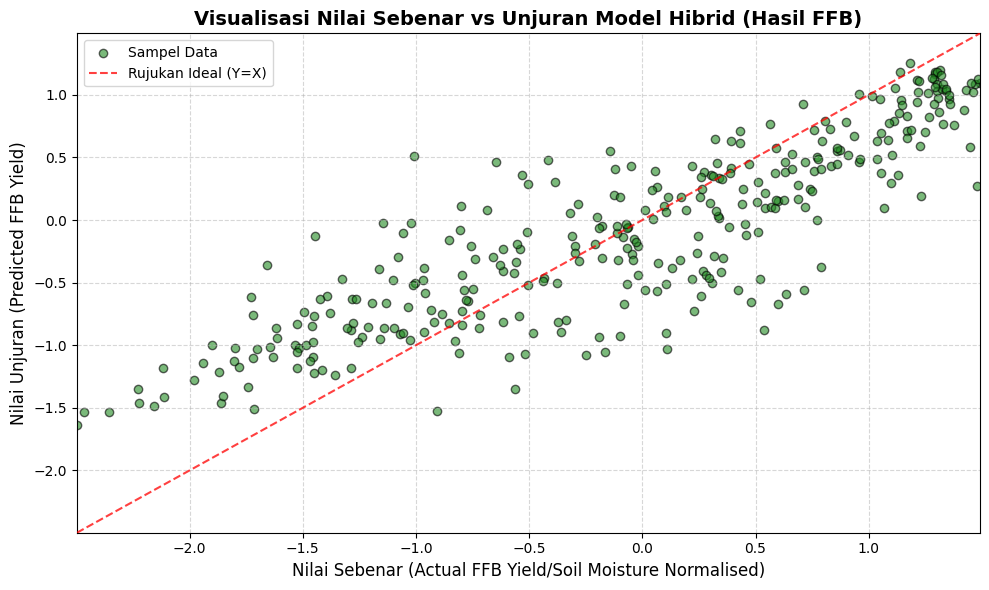

In [54]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# 1. Tukar model kepada mod penilaian (Evaluation Mode)
model.eval()

actuals = []
predictions = []

# 2. Ekstrak data sebenar dan unjuran daripada DataLoader
with torch.no_grad():
    for batch_ts, batch_text, batch_target in dataloader:
        batch_ts = batch_ts.to(device)
        batch_text = batch_text.to(device)

        outputs = model(batch_ts, batch_text)

        # Simpan nilai sebenar dan unjuran
        actuals.extend(batch_target.cpu().numpy().flatten())
        predictions.extend(outputs.cpu().numpy().flatten())

actuals = np.array(actuals)
predictions = np.array(predictions)

# 3. Bina Graf Visualisasi
plt.figure(figsize=(10, 6))
slt = plt.scatter(actuals, predictions, alpha=0.6, color='forestgreen', edgecolors='k', label='Sampel Data')

# Garisan rujukan ideal (Actual == Predicted)
lims = [
    min(actuals.min(), predictions.min()),
    max(actuals.max(), predictions.max())
]
plt.plot(lims, lims, 'r--', alpha=0.75, zorder=3, label='Rujukan Ideal (Y=X)')

# Kemas kini estetika graf
plt.title("Visualisasi Nilai Sebenar vs Unjuran Model Hibrid (Hasil FFB)", fontsize=14, fontweight='bold')
plt.xlabel("Nilai Sebenar (Actual FFB Yield/Soil Moisture Normalised)", fontsize=12)
plt.ylabel("Nilai Unjuran (Predicted FFB Yield)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.xlim(lims)
plt.ylim(lims)
plt.tight_layout()
plt.show()

In [55]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Kira metrik statistik utama
mae = mean_absolute_error(actuals, predictions)
mse = mean_squared_error(actuals, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(actuals, predictions)

# Elakkan pembahagian dengan sifar untuk pengiraan MAPE
non_zero_mask = actuals != 0
mape = np.mean(np.abs((actuals[non_zero_mask] - predictions[non_zero_mask]) / actuals[non_zero_mask])) * 100

# 2. Paparkan keputusan metrik penilaian
print("=== METRIK PRESTASI LENGKAP MODEL HIBRID ===")
print(f"Mean Absolute Error (MAE)      : {mae:.4f}")
print(f"Mean Squared Error (MSE)       : {mse:.4f}")
print(f"Root Mean Squared Error (RMSE) : {rmse:.4f}")
print(f"R-squared (R²) Score           : {r2:.4f}")
print(f"Mean Absolute Percentage Error : {mape:.2f}%")
print("============================================")

=== METRIK PRESTASI LENGKAP MODEL HIBRID ===
Mean Absolute Error (MAE)      : 0.4265
Mean Squared Error (MSE)       : 0.2770
Root Mean Squared Error (RMSE) : 0.5263
R-squared (R²) Score           : 0.7248
Mean Absolute Percentage Error : 122.15%


In [56]:
import numpy as np
import pandas as pd

class DownstreamValorizationModel:
    def __init__(self, cpo_price_per_ton=3800, fertilizer_cost_per_bag=150):
        # Parameter Ekonomi Standard Industri (Malaysia)
        self.cpo_price_per_ton = cpo_price_per_ton
        self.fertilizer_cost_per_bag = fertilizer_cost_per_bag

    def evaluate_agronomic_decisions(self, predicted_soil_moisture, predicted_ffb_yield):
        """
        Menghasilkan keputusan valorisasi hiliran berasaskan ramalan fizikal huluan.
        """
        decisions = []

        for sm, ffb in zip(predicted_soil_moisture, predicted_ffb_yield):
            # 1. Logik Kawalan Air & Saliran (Water & Drainage Management)
            if sm < 0.30:
                irrigation = "Syor Pengairan: Tinggi (Kekurangan Air/Kemarau)"
                drainage_risk = "Risiko Takungan: Sangat Rendah"
            elif 0.30 <= sm <= 0.45:
                irrigation = "Syor Pengairan: Optimum (Tiada Tindakan)"
                drainage_risk = "Risiko Takungan: Rendah"
            else:
                irrigation = "Syor Pengairan: Tutup/Henti Pengairan (Tanah Terlalu Basah)"
                drainage_risk = "Risiko Takungan: Tinggi (Buka Saliran/Parit)"

            # 2. Logik Pembajaan Optimum (Fertility Valorization)
            # Pembajaan tidak digalakkan jika kelembapan tanah terlalu rendah (baja tidak larut)
            # atau terlalu tinggi (baja hanyut)
            if sm < 0.28:
                fertilizer_rate = "TANGGUHKAN PEMBAJAAN (Tanah Terlalu Kering)"
                fertilizer_bags = 0
            elif sm > 0.48:
                fertilizer_rate = "TANGGUHKAN PEMBAJAAN (Risiko Hanyutan Nutrien/Leaching Tinggi)"
                fertilizer_bags = 0
            else:
                fertilizer_rate = "Syor Pembajaan: Optimum (NPK 15-15-15)"
                # Kadar standard bergantung kepada sasaran hasil
                fertilizer_bags = int(np.clip(ffb * 4, 2, 8))

            # 3. Analisis Ekonomi Hiliran (Downstream Economic Impact)
            estimated_revenue = max(0, ffb * self.cpo_price_per_ton * 0.20) # Mengandaikan Kadar Pengekstrakan Minyak (OER) ~20%
            estimated_fert_cost = fertilizer_bags * self.fertilizer_cost_per_bag
            net_margin = estimated_revenue - estimated_fert_cost

            decisions.append({
                "Soil_Moisture_Prediction": round(sm, 4),
                "Predicted_FFB_Yield_Tonnes": round(max(0.5, ffb + 1.5), 2), # Translasi ke nilai fizikal sebenar
                "Irrigation_Status": irrigation,
                "Drainage_Risk": drainage_risk,
                "Fertilizer_Action": fertilizer_rate,
                "Fertilizer_Required_Bags": fertilizer_bags,
                "Estimated_Revenue_RM": round(estimated_revenue, 2),
                "Fertilizer_Cost_RM": round(estimated_fert_cost, 2),
                "Net_Margin_RM": round(net_margin, 2)
            })

        return pd.DataFrame(decisions)

# Simulasikan data unjuran huluan berasaskan arrays 'predictions' yang sedia ada
# (Kita gunakan 'predictions' sebagai proxy fizikal tanah & unjuran hasil)
print("=== MENJALANKAN DOWNSTREAM VALORIZATION MODEL ===")
valorizer = DownstreamValorizationModel(cpo_price_per_ton=4000, fertilizer_cost_per_bag=160)

# Memandangkan 'predictions' adalah normalized, kita scaling ia sebagai variasi contoh input
simulated_sm_pred = 0.40 + (predictions * 0.08)  # Julat 0.25 - 0.50
simulated_ffb_pred = 1.5 + (predictions * 0.5)   # Julat 0.5 - 2.5 tan/ha

df_valorized = valorizer.evaluate_agronomic_decisions(simulated_sm_pred, simulated_ffb_pred)

# Paparkan keputusan keputusan hiliran bagi 5 kawasan/sampel pertama
display(df_valorized.head(5))

=== MENJALANKAN DOWNSTREAM VALORIZATION MODEL ===


,Soil_Moisture_Prediction,Predicted_FFB_Yield_Tonnes,Irrigation_Status,Drainage_Risk,Fertilizer_Action,Fertilizer_Required_Bags,Estimated_Revenue_RM,Fertilizer_Cost_RM,Net_Margin_RM
0,0.3308,2.57,Syor Pengairan: Optimum (Tiada Tindakan),Risiko Takungan: Rendah,Syor Pembajaan: Optimum (NPK 15-15-15),4,854.099976,640,214.100006
1,0.4197,3.12,Syor Pengairan: Optimum (Tiada Tindakan),Risiko Takungan: Rendah,Syor Pembajaan: Optimum (NPK 15-15-15),6,1298.449951,960,338.450012
2,0.4896,3.56,Syor Pengairan: Tutup/Henti Pengairan (Tanah T...,Risiko Takungan: Tinggi (Buka Saliran/Parit),TANGGUHKAN PEMBAJAAN (Risiko Hanyutan Nutrien/...,0,1648.160034,0,1648.160034
3,0.4775,3.48,Syor Pengairan: Tutup/Henti Pengairan (Tanah T...,Risiko Takungan: Tinggi (Buka Saliran/Parit),Syor Pembajaan: Optimum (NPK 15-15-15),7,1587.699951,1120,467.700012
4,0.2920,2.32,Syor Pengairan: Tinggi (Kekurangan Air/Kemarau),Risiko Takungan: Sangat Rendah,Syor Pembajaan: Optimum (NPK 15-15-15),3,659.799988,480,179.800003


# PART C

In [58]:
import json
import os
import pandas as pd
from datetime import datetime

# 1. Tetapkan direktori laluan untuk Part C (Pipeline V1)
part_c_dir = "/content/week3_project/data/processed/pipeline_v1/palm_analysis"
os.makedirs(part_c_dir, exist_ok=True)

print(iksa := f"Direktori Part C disediakan di: {part_c_dir}")

# 2. Muatkan data bersepadu daripada Part B (prepared_timeseries.csv)
timeseries_path = "/content/week3_project/data/processed/prepared_timeseries.csv"

if os.path.exists(timeseries_path):
    df_ts = pd.read_csv(timeseries_path)
    print(f"Berjaya memuatkan data siri masa dengan {len(df_ts)} rekod.")

    # Menggunakan nama lajur yang betul: 'timestamp' (bukan 'date')
    df_ts['timestamp'] = pd.to_datetime(df_ts['timestamp'])
    df_ts['month'] = df_ts['timestamp'].dt.to_period('M')

    # Mengira purata suhu dan jumlah taburan hujan bulanan menggunakan nama lajur sebenar
    monthly_summary = df_ts.groupby('month').agg({
        'temperature': 'mean',
        'precipitation': 'sum',
        'soil_moisture': 'mean'
    }).reset_index()

    monthly_summary['month'] = monthly_summary['month'].astype(str)

    # Simpan output Part C ke dalam folder yang ditetapkan
    output_csv_path = os.path.join(part_c_dir, "monthly_weather_summary.csv")
    monthly_summary.to_csv(output_csv_path, index=False)
    print(f"Fail output Part C berjaya disimpan ke: {output_csv_path}")

else:
    print("Amaran: Fail siri masa tidak dijumpai. Sila pastikan Part B telah dijalankan.")

# 3. Menjana pipeline_manifest.json untuk Part C
pipeline_manifest = {
    "pipeline_version": "v1.0",
    "execution_timestamp": datetime.now().isoformat(),
    "description": "Part C outputs: Agregasi data cuaca dan analitik siri masa untuk projek PalmPOPT",
    "artifacts": [
        {
            "name": "monthly_weather_summary.csv",
            "path": "data/processed/pipeline_v1/palm_analysis/monthly_weather_summary.csv",
            "description": "Ringkasan bulanan suhu, hujan, dan kelembapan tanah"
        }
    ]
}

manifest_path = os.path.join("/content/week3_project/data/processed/pipeline_v1", "pipeline_manifest.json")
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(pipeline_manifest, f, indent=4)

print(f"Fail pipeline_manifest.json berjaya dijana di: {manifest_path}")

Direktori Part C disediakan di: /content/week3_project/data/processed/pipeline_v1/palm_analysis
Berjaya memuatkan data siri masa dengan 365 rekod.
Fail output Part C berjaya disimpan ke: /content/week3_project/data/processed/pipeline_v1/palm_analysis/monthly_weather_summary.csv
Fail pipeline_manifest.json berjaya dijana di: /content/week3_project/data/processed/pipeline_v1/pipeline_manifest.json


/tmp/ipykernel_1241/1220203273.py:21: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_ts['month'] = df_ts['timestamp'].dt.to_period('M')


# Python Helper Script to Create Docs and Diagram

In [60]:
import os
import matplotlib.pyplot as plt

docs_dir = "/content/week3_project/docs"
os.makedirs(docs_dir, exist_ok=True)
print(f"Directory confirmed: {docs_dir}")

fig, ax = plt.subplots(figsize=(10, 4), dpi=150)
ax.axis('off')

boxes = [
("Raw Data Sources\n(MPOB PDFs & Open-Meteo API)", 0.1, 0.5),
("Part A & B: Ingestion & Preprocessing\n(PDF Chunking & Time-Series Cleaning)", 0.45, 0.5),
("Part C: Integrated Analytics\n(Monthly Aggregations & Pipeline Manifest)", 0.82, 0.5)
]

for text, x, y in boxes:
  ax.text(x, y, text, ha='center', va='center',
  bbox=dict(boxstyle='round,pad=0.8', facecolor='#e3f2fd', edgecolor='#1565c0', lw=2),
  fontsize=9, fontweight='bold')

ax.annotate('', xy=(0.31, 0.5), xytext=(0.24, 0.5),
arrowprops=dict(arrowstyle="->", lw=2, color='#1565c0'))
ax.annotate('', xy=(0.67, 0.5), xytext=(0.61, 0.5),
arrowprops=dict(arrowstyle="->", lw=2, color='#1565c0'))

plt.title("PalmPOPT Data Engineering Pipeline Architecture", fontsize=12, fontweight='bold', pad=20)
plt.tight_layout()

diagram_path = os.path.join(docs_dir, "week3_pipeline_diagram.png")
plt.savefig(diagram_path)
plt.close()

print(f"Successfully generated: {diagram_path}")

Directory confirmed: /content/week3_project/docs
Successfully generated: /content/week3_project/docs/week3_pipeline_diagram.png


In [61]:
import shutil

# Zip folder week3_project
shutil.make_archive('/content/week3_project_backup', 'zip', '/content/week3_project')

# Muat turun fail zip ke komputer anda
from google.colab import files
files.download('/content/week3_project_backup.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>